<a href="https://colab.research.google.com/github/natedawg07/MNIST-project/blob/main/MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


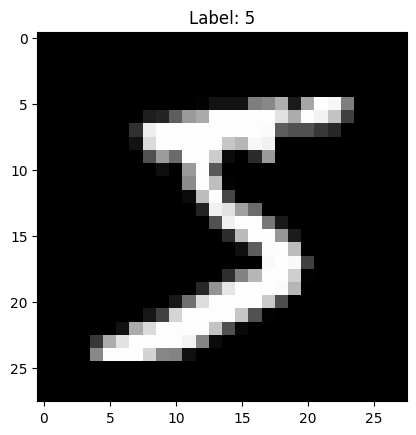

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)

plt.imshow(x_train[0], cmap='gray')
plt.title(f"Label: {y_train[0]}")
plt.show()



In [ ]:
# Normalize the pixel values (0–255 → 0–1)
x_train = x_train / 255.0
x_test = x_test / 255.0

# One-hot encode the labels
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)



In [ ]:
model = Sequential([
Flatten(input_shape=(28, 28)),
Dense(128, activation='relu'),
Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(optimizer='adam',
loss='categorical_crossentropy',
metrics=['accuracy'])

In [ ]:
model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9263 - loss: 0.2615 - val_accuracy: 0.9566 - val_loss: 0.1452
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9651 - loss: 0.1183 - val_accuracy: 0.9690 - val_loss: 0.1045
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9763 - loss: 0.0805 - val_accuracy: 0.9736 - val_loss: 0.0843
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9817 - loss: 0.0589 - val_accuracy: 0.9723 - val_loss: 0.0891
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9858 - loss: 0.0464 - val_accuracy: 0.9769 - val_loss: 0.0769


In [ ]:
loss, accuracy = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9769 - loss: 0.0769
Test Accuracy: 97.69%


In [ ]:
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


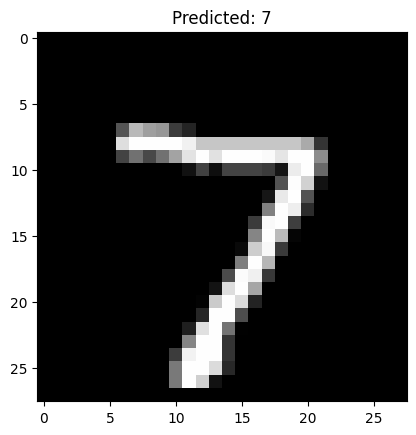

In [ ]:
plt.imshow(x_test[0].reshape(28,28), cmap='gray')
plt.title(f"Predicted: {np.argmax(predictions[0])}")
plt.show()

In [ ]:
# ── Draw-a-digit widget ─────────────────────────────────────────────
# Paste this into a NEW cell at the bottom of the notebook and run it
# after the model has trained. Draw in the black box; the table updates
# each time you lift your mouse / pen / finger.

import base64, io
import numpy as np
from PIL import Image
from scipy import ndimage
from IPython.display import HTML, JSON, display
from google.colab import output


def preprocess(data_url):
    """Canvas drawing -> 28x28 MNIST-style array (white digit on black, values 0-1)."""
    raw = base64.b64decode(data_url.split(",", 1)[1])
    img = np.array(Image.open(io.BytesIO(raw)).convert("L"), dtype=np.float32)

    rows = np.where(img.max(axis=1) > 20)[0]
    cols = np.where(img.max(axis=0) > 20)[0]
    if rows.size == 0:
        return None
    img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]

    h, w = img.shape
    s = 20.0 / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = np.array(
        Image.fromarray(img.astype(np.uint8)).resize((nw, nh), Image.LANCZOS),
        dtype=np.float32,
    )

    out = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - nh) // 2, (28 - nw) // 2
    out[top:top + nh, left:left + nw] = small
    cy, cx = ndimage.center_of_mass(out)
    out = ndimage.shift(out, (np.round(14 - cy), np.round(14 - cx)),
                        order=0, mode="constant", cval=0)
    return np.clip(out / 255.0, 0.0, 1.0)


def to_png(arr28):
    """28x28 array -> small PNG data URL so you can see what the model sees."""
    im = Image.fromarray((arr28 * 255).astype(np.uint8)).resize((112, 112), Image.NEAREST)
    buf = io.BytesIO()
    im.save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()


def predict_digit(data_url):
    x = preprocess(data_url)
    if x is None:
        return JSON({"empty": True})
    probs = model(x[None, ...], training=False).numpy()[0]
    return JSON({"probs": [float(p) for p in probs], "preview": to_png(x)})


output.register_callback("predict_digit", predict_digit)

display(HTML(r"""
<style>
  #dd { display:flex; gap:28px; flex-wrap:wrap; align-items:flex-start;
        font-family: "Times New Roman", Times, serif;
        background:#16181c; color:#e8e8e8; padding:20px; border-radius:12px;
        border:1px solid #2c2f36; width:fit-content; }
  #dd canvas { border-radius:8px; cursor:crosshair; touch-action:none; display:block;
               border:1px solid #3a3e47; }
  #dd .row { display:flex; gap:12px; align-items:center; margin-top:10px; }
  #dd button { font:inherit; font-size:16px; padding:5px 16px; border-radius:6px;
               border:1px solid #444a55; background:#24272e; color:#e8e8e8; cursor:pointer; }
  #dd button:hover { background:#2e323b; }
  #dd .hint { font-size:14px; color:#8b919c; font-style:italic; }
  #dd .guess { font-size:24px; font-weight:700; margin-bottom:4px; min-height:30px; }
  #dd .sub { font-size:15px; color:#9aa0aa; margin-bottom:12px; min-height:20px; }
  #dd table { border-collapse:collapse; font-size:16px; }
  #dd td { padding:3px 6px; color:#e8e8e8; font-family:"Times New Roman", Times, serif; }
  #dd td.dig { font-weight:700; width:18px; text-align:center; }
  #dd td.pct { width:62px; text-align:right; color:#b8bdc6; }
  #dd .track { width:200px; height:14px; background:#2a2d34; border-radius:7px; overflow:hidden; }
  #dd .fill { height:100%; width:0; background:#6b7280; border-radius:7px; transition:width .15s; }
  #dd tr.top .fill { background:#5aa2ff; }
  #dd tr.top td.dig, #dd tr.top td.pct { color:#5aa2ff; font-weight:700; }
  #dd .seen { display:flex; gap:10px; align-items:center; margin-top:14px; font-size:14px; color:#8b919c; }
  #dd .seen img { image-rendering:pixelated; border-radius:4px; background:#000; width:56px; height:56px;
                  border:1px solid #3a3e47; }
</style>

<div id="dd">
  <div>
    <canvas id="dd-canvas" width="280" height="280"></canvas>
    <div class="row">
      <button id="dd-clear">Clear</button>
      <span class="hint">Draw one digit, fairly large</span>
    </div>
  </div>
  <div>
    <div class="guess" id="dd-guess">Draw a digit</div>
    <div class="sub" id="dd-sub"></div>
    <table id="dd-table"></table>
    <div class="seen"><img id="dd-preview" alt=""><span>what the model sees (28×28)</span></div>
  </div>
</div>

<script>
(() => {
  const canvas  = document.getElementById('dd-canvas');
  const ctx     = canvas.getContext('2d');
  const table   = document.getElementById('dd-table');
  const guess   = document.getElementById('dd-guess');
  const sub     = document.getElementById('dd-sub');
  const preview = document.getElementById('dd-preview');

  // Build the 0-9 table once
  const rows = [];
  for (let d = 0; d <= 9; d++) {
    const tr = document.createElement('tr');
    tr.innerHTML = `<td class="dig">${d}</td>
                    <td><div class="track"><div class="fill"></div></div></td>
                    <td class="pct">0.0%</td>`;
    table.appendChild(tr);
    rows.push({ tr, fill: tr.querySelector('.fill'), pct: tr.querySelector('.pct') });
  }

  const fmt = p => (p < 0.001 ? '<0.1%' : (p * 100).toFixed(1) + '%');

  function render(d) {
    if (!d) {
      rows.forEach(r => { r.tr.classList.remove('top'); r.fill.style.width = '0'; r.pct.textContent = '0.0%'; });
      guess.textContent = 'Draw a digit';
      sub.textContent = '';
      preview.removeAttribute('src');
      return;
    }
    const p = d.probs;
    const order = [...p.keys()].sort((a, b) => p[b] - p[a]);
    rows.forEach((r, i) => {
      r.tr.classList.toggle('top', i === order[0]);
      r.fill.style.width = (p[i] * 100).toFixed(1) + '%';
      r.pct.textContent = fmt(p[i]);
    });
    guess.textContent = `Looks like a ${order[0]}  (${fmt(p[order[0]])})`;
    sub.textContent = p[order[1]] >= 0.05 ? `runner-up: ${order[1]} (${fmt(p[order[1]])})` : '';
    preview.src = d.preview;
  }

  function clearCanvas() {
    ctx.fillStyle = '#000';
    ctx.fillRect(0, 0, canvas.width, canvas.height);
    render(null);
  }

  ctx.lineWidth = 22;
  ctx.lineCap = 'round';
  ctx.lineJoin = 'round';
  ctx.strokeStyle = '#fff';
  clearCanvas();

  let drawing = false, last = null, busy = false, again = false;

  const pos = e => {
    const r = canvas.getBoundingClientRect();
    return [(e.clientX - r.left) * canvas.width / r.width,
            (e.clientY - r.top)  * canvas.height / r.height];
  };

  canvas.addEventListener('pointerdown', e => {
    drawing = true;
    canvas.setPointerCapture(e.pointerId);
    last = pos(e);
    ctx.fillStyle = '#fff';
    ctx.beginPath();
    ctx.arc(last[0], last[1], ctx.lineWidth / 2, 0, 2 * Math.PI);
    ctx.fill();
  });

  canvas.addEventListener('pointermove', e => {
    if (!drawing) return;
    const p = pos(e);
    ctx.beginPath();
    ctx.moveTo(last[0], last[1]);
    ctx.lineTo(p[0], p[1]);
    ctx.stroke();
    last = p;
  });

  const endStroke = () => { if (!drawing) return; drawing = false; predict(); };
  canvas.addEventListener('pointerup', endStroke);
  canvas.addEventListener('pointercancel', endStroke);

  document.getElementById('dd-clear').addEventListener('click', clearCanvas);

  async function predict() {
    if (busy) { again = true; return; }
    busy = true;
    try {
      const res = await google.colab.kernel.invokeFunction(
        'predict_digit', [canvas.toDataURL('image/png')], {});
      const d = res.data['application/json'];
      render(d.empty ? null : d);
    } catch (err) {
      guess.textContent = 'Prediction failed';
      sub.textContent = String(err);
    }
    busy = false;
    if (again) { again = false; predict(); }
  }
})();
</script>
"""))